# Bitcoin, Monero e Google Trends: risultati

Questo notebook esegue in locale, sui CSV di `data/`, la stessa logica dei job AWS Glue (modulo `src/cripto.py`) e ne mostra i risultati:

1. **Qualità dei dati**: periodo, giorni mancanti, prezzi non validi.
2. **Pulizia**: sostituzione dei prezzi non validi (-1) e confronto con il metodo della prima versione della pipeline.
3. **Media mobile e unione settimanale** con Google Trends.
4. **Analisi**: relazione tra prezzo e interesse, confronto tra Bitcoin e Monero.

Non serve un account AWS: le tabelle prodotte sono le stesse che la pipeline carica in Redshift.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cripto

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 90
COLORI = {"bitcoin": "#f2a900", "monero": "#ff6600"}
DATA = ROOT / "data"

grezzi, puliti, trend, tabelle = {}, {}, {}, {}
for m in cripto.CRIPTO.values():
    grezzi[m.nome] = cripto.leggi_prezzi(DATA / m.file_prezzi)
    puliti[m.nome] = cripto.pulisci_prezzi(grezzi[m.nome])
    trend[m.nome] = cripto.leggi_trend(DATA / m.file_trend, m.colonna_trend)
    tabelle[m.nome] = cripto.tabelle_finali(puliti[m.nome], trend[m.nome])
grezzi["bitcoin"].head()

,data,prezzo
0,2024-03-12,"65,619.50"
1,2024-03-11,"65,859.90"
2,2024-03-10,"63,074.30"
3,2024-03-09,"62,649.90"
4,2024-03-08,"62,413.80"


## 1. Qualità dei dati

I prezzi giornalieri vengono da Investing.com, con le date nel formato mese/giorno/anno e, per Bitcoin, la virgola come separatore delle migliaia (`65,619.5`). Google Trends fornisce un indice settimanale da 0 a 100, riferito alla settimana che inizia ogni domenica.

In [2]:
qualita = pd.DataFrame({nome: cripto.report_qualita(df) for nome, df in grezzi.items()})
qualita.loc["settimane_google_trends"] = [len(trend[n]) for n in qualita.columns]
qualita

,bitcoin,monero
righe,1887,1898
dal,2019-01-12,2019-01-01
al,2024-03-12,2024-03-12
date_duplicate,0,0
giorni_mancanti,0,0
prezzi_non_validi,18,22
settimane_google_trends,260,260


In [3]:
righe = []
for nome, df in puliti.items():
    stimati = df[df["prezzo_stimato"]]
    righe.append({"moneta": nome, "prezzi non validi": len(stimati),
                  "primo": stimati["data"].min().date(), "ultimo": stimati["data"].max().date()})
pd.DataFrame(righe).set_index("moneta")

,prezzi non validi,primo,ultimo
moneta,,,
bitcoin,18,2023-07-22,2024-02-23
monero,22,2023-03-22,2024-01-30


Non ci sono giorni mancanti né duplicati, ma ci sono 18 prezzi -1 per Bitcoin e 22 per Monero, tutti concentrati nell'ultimo anno.

## 2. Pulizia dei prezzi non validi

I prezzi -1 vengono sostituiti per **interpolazione lineare** tra il giorno valido precedente e quello successivo, dopo aver ordinato i dati per data (i file originali sono in ordine decrescente).

La prima versione della pipeline sostituiva ogni -1 con la media dei 5 prezzi "precedenti". Il ciclo però riordinava il DataFrame durante la sostituzione e continuava a usare le posizioni delle righe nell'ordine originale. Qui sotto il metodo originale, riprodotto così com'era, è confrontato con quello corretto:

In [4]:
def metodo_originale(df):
    # Ciclo della prima versione (jobBTC_step1.py), applicato ai dati in ordine originale
    df = df.copy()
    for index, row in df.iterrows():
        if row["prezzo"] == -1:
            precedenti = df["prezzo"].iloc[max(0, index - 5):index].dropna()
            if not precedenti.empty:
                df.loc[index, "prezzo"] = precedenti.mean()
                df.sort_values(by="data", inplace=True)
            else:
                df.loc[index, "prezzo"] = df["prezzo"].mean()
    return df


confronti = []
for nome in grezzi:
    originale = metodo_originale(grezzi[nome]).set_index("data")["prezzo"]
    corretto = puliti[nome].set_index("data")
    stimati = corretto[corretto["prezzo_stimato"]].index
    confronti.append(pd.DataFrame({
        "moneta": nome,
        "metodo originale": originale[stimati],
        "interpolazione": corretto.loc[stimati, "prezzo"],
    }))
confronto = pd.concat(confronti)
confronto["errore originale"] = confronto["metodo originale"] / confronto["interpolazione"] - 1
confronto.groupby("moneta")["errore originale"].describe(percentiles=[0.5])[["count", "min", "50%", "max"]].style.format("{:.0%}", subset=["min", "50%", "max"])

,count,min,50%,max
moneta,,,,
bitcoin,18.000000,-93%,-72%,8%
monero,22.000000,-71%,-56%,0%


In [5]:
confronto[confronto["moneta"] == "bitcoin"].sort_index().tail(8)

,moneta,metodo originale,interpolazione,errore originale
data,,,,
2023-11-21,bitcoin,"4,787.80","34,312.55",-0.86
2023-12-06,bitcoin,"4,593.80","40,478.05",-0.89
2023-12-12,bitcoin,"4,604.62","38,875.10",-0.88
2023-12-28,bitcoin,"3,512.18","38,686.95",-0.91
2024-01-01,bitcoin,"3,521.88","39,757.50",-0.91
2024-01-23,bitcoin,"3,346.52","36,571.65",-0.91
2024-02-10,bitcoin,"3,154.42","44,114.50",-0.93
2024-02-23,bitcoin,"51,116.60","47,495.95",0.08


Con il metodo originale quasi tutti i prezzi stimati erano molto più bassi del reale, in mediana del 72% per Bitcoin e del 56% per Monero: per esempio il 10/02/2024 Bitcoin valeva circa 44.000 €, ma il prezzo stimato era 3.154 €, la media di 5 prezzi del 2019. Con l'interpolazione ogni prezzo stimato sta tra quelli dei giorni vicini.

## 3. Media mobile e unione settimanale

La media mobile a 10 giorni usa il giorno stesso e i 9 precedenti, mai i giorni futuri. Per l'unione con Google Trends i prezzi vengono aggregati sulla stessa settimana dell'indice, da domenica a sabato: prezzo medio, prezzo di chiusura e variazione rispetto alla settimana precedente.

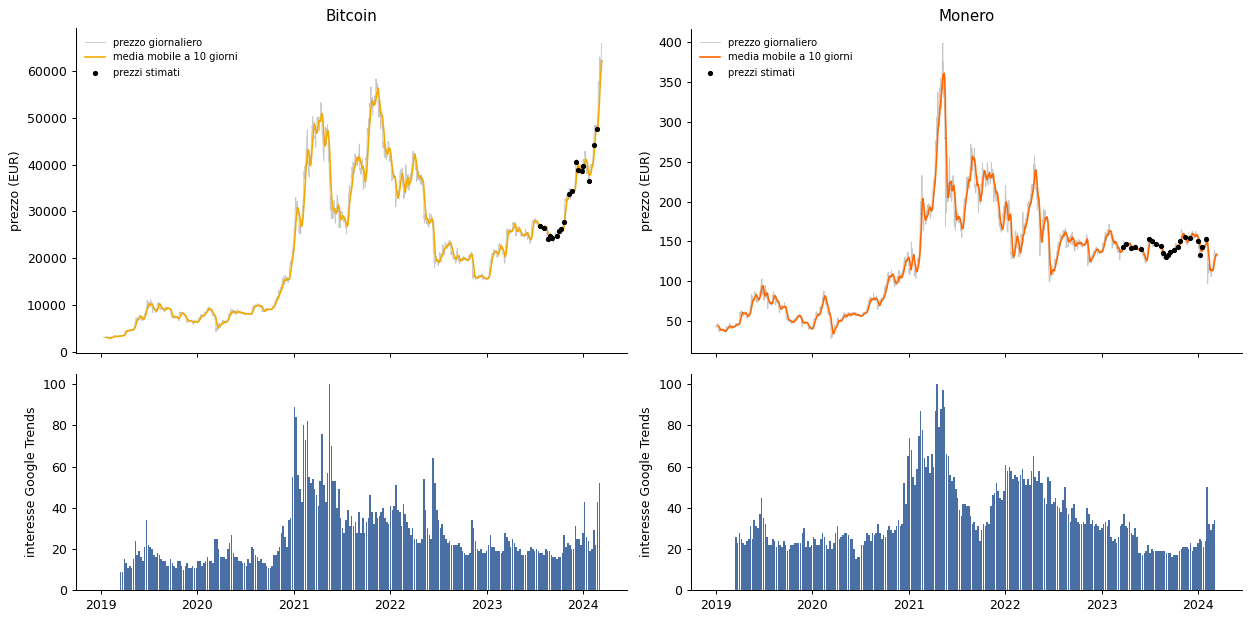

In [6]:
fig, assi = plt.subplots(2, 2, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for colonna, nome in enumerate(tabelle):
    giornaliero, settimanale = tabelle[nome]["prezzi_giornalieri"], tabelle[nome]["settimanale"]
    alto, basso = assi[0, colonna], assi[1, colonna]
    alto.plot(giornaliero["data"], giornaliero["prezzo"], color="#c8c8c8", lw=0.7, label="prezzo giornaliero")
    alto.plot(giornaliero["data"], giornaliero["media_mobile_10g"], color=COLORI[nome], lw=1.3,
              label="media mobile a 10 giorni")
    stimati = giornaliero[giornaliero["prezzo_stimato"]]
    alto.scatter(stimati["data"], stimati["prezzo"], color="black", s=10, zorder=3, label="prezzi stimati")
    alto.set_title(nome.title())
    alto.set_ylabel("prezzo (EUR)")
    alto.legend(loc="upper left", frameon=False, fontsize=8)
    basso.bar(settimanale["settimana"], settimanale["interesse"], width=6, color="#4a6fa5")
    basso.set_ylabel("interesse Google Trends")
    for asse in (alto, basso):
        asse.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
tabelle["bitcoin"]["settimanale"].tail()

,settimana,prezzo_medio,prezzo_chiusura,variazione_pct,interesse,giorni_stimati
255,2024-02-04,"41,458.07","44,114.50",10.75,20,1
256,2024-02-11,"47,171.47","47,944.20",8.68,29,0
257,2024-02-18,"47,880.99","47,621.90",-0.67,22,1
258,2024-02-25,"54,187.94","57,223.20",20.16,43,0
259,2024-03-03,"60,974.14","62,649.90",9.48,52,0


Le due tabelle per moneta, `prezzi_giornalieri` e `settimanale`, sono quelle che il job `carica_redshift` carica negli schemi `bitcoin` e `monero` di Redshift. Ogni tabella settimanale ha 260 settimane complete, dal 17/03/2019 al 03/03/2024.

## 4. Analisi

### Prezzo e interesse per anno

In [8]:
annuale = {}
for nome in tabelle:
    s = tabelle[nome]["settimanale"]
    annuale[nome] = s.groupby(s["settimana"].dt.year)[["prezzo_medio", "interesse"]].mean()
pd.concat(annuale, axis=1).rename_axis("anno")

bitcoin                 monero          
     prezzo_medio interesse prezzo_medio interesse
anno                                              
2019     7,447.89     14.76        63.46     25.48
2020     9,760.64     18.27        74.25     27.33
2021    40,284.82     46.60       210.08     53.88
2022    26,401.98     29.40       156.08     45.50
2023    26,877.51     20.53       145.74     23.06
2024    45,397.80     30.89       132.15     30.11

- Per **Monero** prezzo e interesse hanno il massimo nello stesso periodo, aprile-maggio 2021.
- Per **Bitcoin** il prezzo raggiunge il massimo a marzo 2024, ma l'interesse medio del 2024 (31) resta sotto quello del 2021 (47): il nuovo record di prezzo non ha riportato l'attenzione ai livelli del 2021.

### Correlazioni

In [9]:
pd.DataFrame({nome: cripto.statistiche(tabelle[nome]["settimanale"]) for nome in tabelle}).T

,settimane,correlazione_prezzo_interesse,correlazione_variazioni,correlazione_variazione_assoluta_interesse
bitcoin,260.00,0.61,-0.03,0.38
monero,260.00,0.62,0.03,0.36


- `correlazione_prezzo_interesse`: prezzo medio settimanale e interesse sono correlati (circa 0,6), soprattutto perché seguono gli stessi cicli di lungo periodo.
- `correlazione_variazioni`: la variazione settimanale del prezzo e quella dell'interesse non sono correlate. L'interesse non indica la direzione del prezzo.
- `correlazione_variazione_assoluta_interesse`: l'interesse cresce con l'ampiezza dei movimenti del prezzo, al rialzo o al ribasso.

### Interesse e ampiezza delle variazioni del prezzo

In [10]:
classi = {}
for nome in tabelle:
    s = tabelle[nome]["settimanale"].dropna(subset=["variazione_pct"])
    classe = pd.cut(s["variazione_pct"].abs(), [0, 5, 10, np.inf], right=False,
                    labels=["meno del 5%", "dal 5 al 10%", "oltre il 10%"])
    classi[nome] = s.groupby(classe, observed=True)["interesse"].agg(settimane="size", interesse_medio="mean")
classi = pd.concat(classi, axis=1).rename_axis("variazione settimanale")
classi

bitcoin                    monero                
                       settimane interesse_medio settimane interesse_medio
variazione settimanale                                                    
meno del 5%                  140           22.40       115           31.33
dal 5 al 10%                  58           27.72        77           33.43
oltre il 10%                  62           34.58        68           43.75

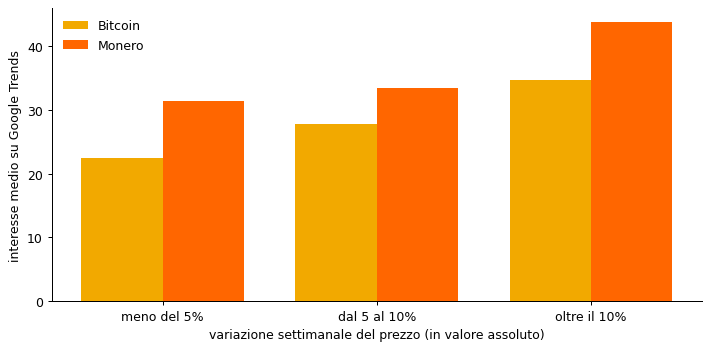

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(classi))
for i, nome in enumerate(tabelle):
    ax.bar(x + (i - 0.5) * 0.38, classi[(nome, "interesse_medio")], width=0.38, color=COLORI[nome], label=nome.title())
ax.set_xticks(x, classi.index)
ax.set_xlabel("variazione settimanale del prezzo (in valore assoluto)")
ax.set_ylabel("interesse medio su Google Trends")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [12]:
# Le 5 settimane di massimo interesse per Bitcoin
tabelle["bitcoin"]["settimanale"].nlargest(5, "interesse")[["settimana", "interesse", "prezzo_medio", "variazione_pct"]]

,settimana,interesse,prezzo_medio,variazione_pct
113,2021-05-16,100,"33,486.09",-19.97
94,2021-01-03,89,"29,495.04",23.96
95,2021-01-10,84,"30,164.44",-7.23
101,2021-02-21,82,"41,249.23",-16.94
99,2021-02-07,80,"37,703.64",19.76


Nelle settimane con variazioni del prezzo oltre il 10% l'interesse medio per Bitcoin è superiore del 54% rispetto alle settimane con variazioni sotto il 5%. La settimana di massimo interesse (100, 16/05/2021) è anche la quinta peggiore su 260, con il -20%: l'attenzione cresce con i movimenti forti, sia al rialzo sia al ribasso.

### Bitcoin e Monero a confronto

In [13]:
unito = tabelle["bitcoin"]["settimanale"].merge(tabelle["monero"]["settimanale"], on="settimana", suffixes=("_btc", "_xmr"))
pd.Series({
    "correlazione dei prezzi medi": unito["prezzo_medio_btc"].corr(unito["prezzo_medio_xmr"]),
    "correlazione delle variazioni settimanali": unito["variazione_pct_btc"].corr(unito["variazione_pct_xmr"]),
    "correlazione dell'interesse": unito["interesse_btc"].corr(unito["interesse_xmr"]),
}).to_frame("valore")

,valore
correlazione dei prezzi medi,0.85
correlazione delle variazioni settimanali,0.67
correlazione dell'interesse,0.83


I prezzi delle due monete si muovono insieme anche settimana per settimana, non solo nel lungo periodo: la correlazione delle variazioni settimanali è 0,67. Anche l'interesse su Google Trends per le due monete è molto correlato (0,83).